Circadian cycle analysis using unfiltered PLV features. Cycle amplitude and peak is computed using Lomb Scarlge are loaded from a precomputed file. Outcomes files from April 8 onwards used.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms

import seaborn as sns
import os
import datetime
import pickle

from scipy.stats import pearsonr
from scipy.stats import ranksums, ttest_ind, ks_2samp, mannwhitneyu
from scipy.stats import linregress
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

import scipy
import itertools
import collections

# import pykalman

from astropy.timeseries import LombScargle
from astropy.stats.circstats import circmean, circvar
from scipy.signal import hilbert

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.visualize import cycleviz

## Supporting function

In [5]:
#### Last updated on 6/21/2026 to align with the definition in Ankit's STM paper
def szred_to_responder(rednum):
    if rednum > 0.9:
        return 'SR'
    elif rednum < 0.5:
        return 'NR'
    else:
        return 'IR'

## Data loaders

In [6]:
save_flag = False

In [7]:
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
patient_list = ccutils.final_patient_list()

# outcome for patients included in the analysis
lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

print(f'Num patients to start with: {len(patient_list)}')

Num patients to start with: 38


In [9]:
# read the cycle charateristics csv file and store in a dictionary

keep_broadband_flag = False
MIN_LS_NSAMP = 120   # 120 MAGIC number for interval computation
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']

lsdf_dict = {}
remove_patids = []

for patient_id in patient_list:
    
    if os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: Exists.')
    else:
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        remove_patids.append(patient_id)
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()
    
# remove patients from the list because file doesnt exist
for patient_id in remove_patids:
    patient_list.remove(patient_id)

NPE0001: Exists.
NPE0005: Exists.
NPE0015: Exists.
NPE0017: Exists.
NPE0019: Exists.
NPE0021: Exists.
NPE0029: Exists.
NPE0034: Exists.
NPE0036: Exists.
NPE0038: Exists.
NPE0039: Exists.
NPE0041: Exists.
NPE0043: Exists.
NPE0045: Exists.
NPE0047: Exists.
NPE0052: Exists.
NPE0055: Exists.
NPE0056: Exists.
NPE0061: Exists.
NPE0062: Exists.
NPE0063: Exists.
NPE0068: Exists.
NPE0070: Exists.
NPE0072: Exists.
NPE0086: Exists.
NPE0087: Exists.
NPE0088: Exists.
NPE0091: Exists.
NPE0095: Exists.
NPE0096: Exists.
NPE0099: Exists.
NPE0102: Exists.
NPE0103: Exists.
NPE0104: Exists.
NPE0120: Exists.
NPE0123: Exists.
NPE0125: Exists.
NPE0140: Exists.


In [10]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs
subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [11]:
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']
tltype = 'causal'  # 'causal' or 'noncausal'
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red', 
                'auc'] # 'auc' included as dummy
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)
lgfeatdf['auc'] = 1 ### dummy value

# combine features with seizure reduction information
mregdf = ccutils.create_cop_dataframe(lgpatcodesdf, lgfeatdf, patient_list, mreg_id_vars, mreg_value_vars, tltype, 
                                      verbose=True)

Dropped nans in regdf: 0


In [12]:
hypencols = [item for item in mregdf.columns if '-' in item]
hypenrename = dict(zip(hypencols, [item.replace('-','_') for item in hypencols]))
mregdf.rename(columns=hypenrename, inplace=True)

In [13]:
response_color_dict = {'SR':'tab:blue', 'IR':'purple', 'NR':'tab:red'}

### Individual patient - NPE0096

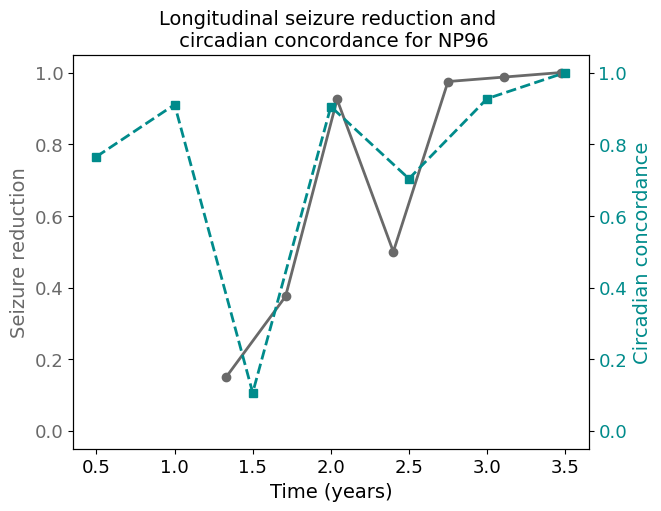

In [14]:
bdoi = 'alpha'
feature = 'peakhour_local'
outcome = 'sz_red'
fig_ylim = [-0.05, 1.05]

peak_sync_color = 'darkcyan'
sz_red_color = 'dimgrey'

fig, ax = plt.subplots(1, 1, figsize=(6.5,5), layout='constrained')

#### patient 1
patid = 'NPE0096'
outdf = lgpatcodesdf.loc[lgpatcodesdf['npe_code']==patid].copy()
outdf['yrs_from_implant'] = outdf['days_from_implant'].apply(lambda x: round(x / 365, 2))
featdf = lgfeatdf.loc[(lgfeatdf['npecode']==patid) & (lgfeatdf['band']==bdoi)].copy()
featdf['yrs_from_implant'] = featdf['days_from_implant'].apply(lambda x: round(x / 365, 2))

lns1 = ax.plot(outdf['yrs_from_implant'], outdf['sz_red'], '-o', 
                   linewidth=2, color=sz_red_color)
ax.set_ylim(fig_ylim)
ax.set_ylabel('Seizure reduction', fontsize=14, color=sz_red_color)
ax.tick_params(axis='y', labelsize=13, labelcolor=sz_red_color)

ax0_2 = ax.twinx()
lns2 = ax0_2.plot(featdf['yrs_from_implant'], featdf['peakhour_local'], '--s', 
                  linewidth=2, color=peak_sync_color)
ax0_2.set_ylim(fig_ylim)
ax0_2.set_ylabel('Circadian concordance', fontsize=14, color=peak_sync_color)
ax0_2.tick_params(axis='y', labelsize=13, labelcolor=peak_sync_color)

ax.set_xlabel('Time (years)', fontsize=14)
ax.tick_params(axis='x', labelsize=13)

ax.set_title(f'Longitudinal seizure reduction and \n circadian concordance for {utils.format_patid(patid)}', fontsize=14)

if save_flag:
    fig.savefig(outsupfig_dir + f'circbio_individual_patient_{patid}.pdf', dpi=300)

plt.show()

### Distribution of difference between left and right vs seizure reduction groups

In [15]:
## dataframe with peak hour infromation from alpha band
hrdiffdf = {key:[] for key in ['npecode', 'feat_days', 'sz_red', 'peakhour_local-org', 'peakhour_left', 'peakhour_right']}

for patient_id in patient_list:
    tempdf = lsdf_dict[patient_id].copy()

    for idx, row in mregdf.loc[mregdf['npecode']==patient_id].iterrows():
        # inherited information
        hrdiffdf['npecode'].append(row['npecode'])
        hrdiffdf['feat_days'].append(row['feat_days'])
        hrdiffdf['sz_red'].append(row['sz_red'])
        hrdiffdf['peakhour_local-org'].append(row['peakhour_local_alpha'])
        
        # left and right cycles
        hrdiffdf['peakhour_left'].append(tempdf.loc[tempdf['feature']=='Ch_1-Ch_2_alpha']['peakhour_%d'%(row['feat_days'])].item())
        hrdiffdf['peakhour_right'].append(tempdf.loc[tempdf['feature']=='Ch_3-Ch_4_alpha']['peakhour_%d'%(row['feat_days'])].item())

# convert to dataframe
hrdiffdf = pd.DataFrame(hrdiffdf)


## verification
hrdiffdf['circcon'] = hrdiffdf.apply(lambda x: ccutils.peak_sync_from_hours(x['peakhour_left'], x['peakhour_right']), axis=1) 

if (hrdiffdf['circcon'] - hrdiffdf['peakhour_local-org']).abs().sum() > 1e-14:
    print('There is a problem')
else:
    print('All good')


### include responder status and difference between peaks in hours
hrdiffdf['Responder_Type'] = hrdiffdf['sz_red'].apply(lambda x: szred_to_responder(x))
hrdiffdf['hour_difference'] = hrdiffdf.apply(lambda x: min( abs(x['peakhour_left'] - x['peakhour_right']), 
                                                            24 - abs(x['peakhour_left'] - x['peakhour_right']) ), axis=1)

All good


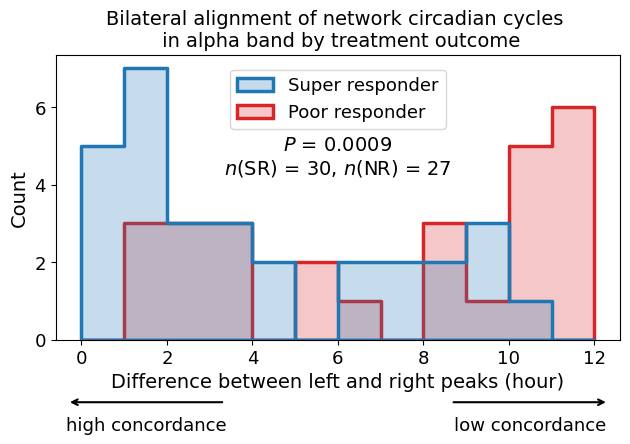

In [16]:
hrszplotdf = hrdiffdf.loc[hrdiffdf['Responder_Type'].isin(['SR', 'NR'])].copy()

# Kolmogorov-Smirnov test
hrsz_group1 = hrszplotdf.loc[hrszplotdf['Responder_Type']=='SR']['hour_difference']
hrsz_group2 = hrszplotdf.loc[hrszplotdf['Responder_Type']=='NR']['hour_difference']
statout = mannwhitneyu(hrsz_group1, hrsz_group2)

# plot the distribution
hueorder = ['SR', 'NR']
fig, ax = plt.subplots()
sns.histplot(data=hrszplotdf, x='hour_difference', hue='Responder_Type', bins=np.linspace(0,12,num=13), 
             hue_order=hueorder, palette=response_color_dict, ax=ax, element='step', fill=True, linewidth=2.5)

# annotate p-value and group sizes
annot_text = f'$P$ = {statout.pvalue:.1g}\n$n$(SR) = {len(hrsz_group1)}, $n$(NR) = {len(hrsz_group2)}'
ax.text(x=0.5, y=0.58, s=annot_text, transform=ax.transAxes, fontsize=14, ha='center')

plt.xlabel('Difference between left and right peaks (hour)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tick_params(labelsize=13)

# reposition legend to the top of the axes, above where the p-value text will go
leg = ax.get_legend()
handles = leg.legend_handles if hasattr(leg, 'legend_handles') else leg.legendHandles
leg.remove()
new_labels = ['Super responder', 'Poor responder']  # matches hueorder = ['SR', 'NR']
leg = ax.legend(handles=handles, labels=new_labels, fontsize=13, title=None,
                 loc='upper center', bbox_to_anchor=(0.5, 0.98),
                 frameon=True)

# directional arrows below the x-axis label, with labels below the arrows
arrow_y = -0.22   # axes-fraction coords; more negative = further below the xlabel
label_y = -0.30   # further below arrow_y so the text sits under the arrow

left_xy, left_xytext = (0.02, arrow_y), (0.30, arrow_y)
right_xy, right_xytext = (0.98, arrow_y), (0.70, arrow_y)

ax.annotate('', xy=left_xy, xytext=left_xytext,
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
            annotation_clip=False)
ax.annotate('', xy=right_xy, xytext=right_xytext,
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
            annotation_clip=False)

left_center_x = (left_xy[0] + left_xytext[0]) / 2
right_center_x = (right_xy[0] + right_xytext[0]) / 2

ax.text(left_center_x, label_y, 'high concordance', transform=ax.transAxes,
        fontsize=13, ha='center', va='center', clip_on=False)
ax.text(right_center_x, label_y, 'low concordance', transform=ax.transAxes,
        fontsize=13, ha='center', va='center', clip_on=False)
ax.set_title('Bilateral alignment of network circadian cycles \n in alpha band by treatment outcome', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outsupfig_dir + 'circbio_peakdifference_by_responders.pdf', dpi=300)
    
plt.show()

### Scatterplot for Circadian Concordance

PearsonRResult(statistic=0.3811780229499903, pvalue=0.0006257219169678794)
Num samples: 77


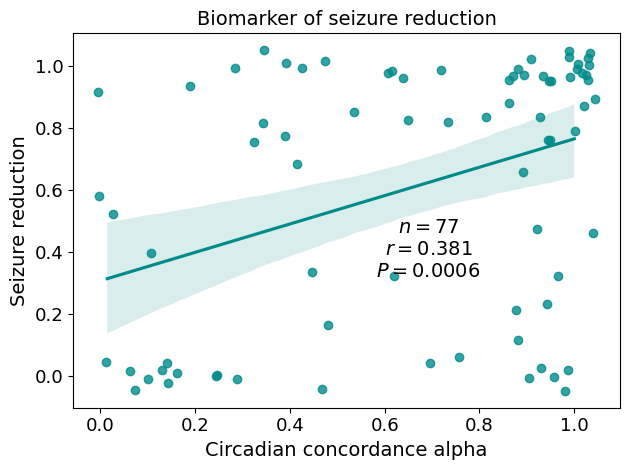

In [17]:
xfeat = 'peakhour_local_alpha'
yvar = 'sz_red'
band = 'alpha'

xcorr = mregdf[xfeat].values
ycorr = mregdf[yvar].values
n_samp = len(xcorr)

corrres = pearsonr(xcorr, ycorr)
print(corrres)
print(f'Num samples: {len(xcorr)}')

ax = sns.regplot(x=xfeat, y=yvar, data=mregdf, color='darkcyan', x_jitter=0.05, y_jitter=0.05)


plt.text(x=0.65, y=0.35, 
         s='$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(n_samp, corrres.statistic, corrres.pvalue), 
         transform=ax.transAxes, fontsize=14, ha='center')

plt.xlabel(f'Circadian concordance {band}', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)

ax.set_title('Biomarker of seizure reduction', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'circbio_cc_alpha_jointplot_jittered.pdf', dpi=300)

plt.show()

In [18]:
rmcorr = utils.corr_repeated_measures(data=mregdf, x="peakhour_local_alpha", y='sz_red', groups='npecode')
print(f"Correlation={rmcorr['corr']}, pvalue={rmcorr['pvalue']}")

Correlation=0.34850399541599264, pvalue=0.0006587981406915122


### Scatterplot for gamma amp

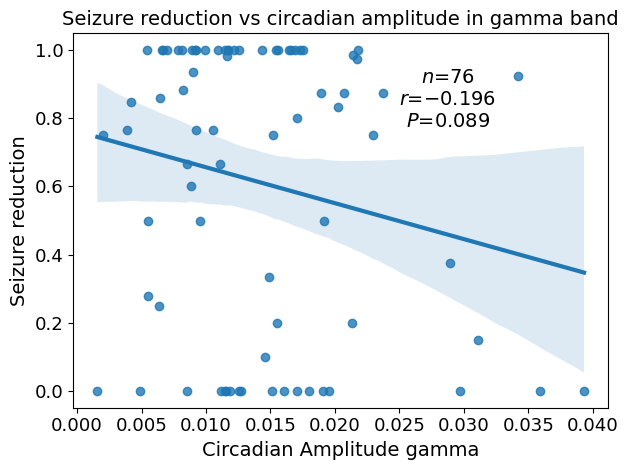

In [19]:
xfeat = 'amp_unnorm_local_gamma'
yvar = 'sz_red'

gamscatplot = mregdf.loc[mregdf[xfeat] < 0.06].copy()  # remove outlier data point

corrval = pearsonr(gamscatplot[xfeat], gamscatplot[yvar])

# model prediction
ax = sns.regplot(data=gamscatplot, x=xfeat, y=yvar, line_kws={'linewidth':3})

# annotations
ax.text(x=0.7, y=0.75, s='$n$=%d\n$r$=$%0.3f$\n$P$=%0.3f'%(gamscatplot.shape[0], corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel('Circadian Amplitude gamma', fontsize=14)
ax.set_ylabel('Seizure reduction', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('Seizure reduction vs circadian amplitude in gamma band', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'circbio_ca_gamma_scatter.pdf', dpi=300)

plt.show()

### Relationship between difference in left and right peak in hours and circadian concordance

In [20]:
resolution = 30
arr_1 = np.zeros(resolution)
arr_2 = np.linspace(0,12,num=resolution)
diff_arr = arr_2 - arr_1
peaksync_arr = np.array( [1 - circvar( np.pi/12 * np.array([arr_1[ii], arr_2[ii]]) ) for ii in range(resolution)] )

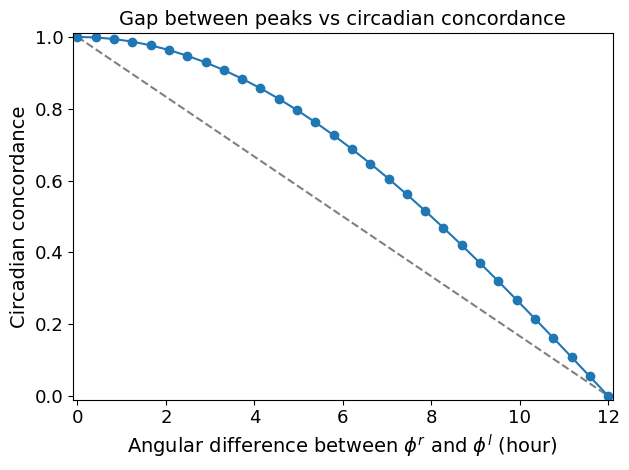

In [21]:
# plotting
plt.plot(np.linspace(0, 12, num=50), np.linspace(1, 0, num=50), linestyle='--', color='gray')
plt.plot(diff_arr, peaksync_arr, '-o')

plt.xlim([-0.1,12.1])
plt.ylim([-0.01, 1.01])
plt.xlabel('Angular difference between $\phi^{r}$ and $\phi^{l}$ (hour)', fontsize=14)
plt.ylabel('Circadian concordance', fontsize=14)
plt.title('Gap between peaks vs circadian concordance', fontsize=14)
plt.tick_params(labelsize=13)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'circbio_cc_time_relationship.pdf', dpi=300)
    
plt.show()